# 06 — Optimisation and final evaluation

The provisional champion is the approved model with the highest Phase 5 validation macro-F1. This notebook tunes only that model. The search uses chronological folds inside the 2023–2024 training period and macro-F1. It does not read the 2025 validation labels while it is choosing hyperparameters, and it does not read the locked test.

`ParameterSampler` draws the random trials. A shuffled `RandomizedSearchCV` is not used, because a random K-fold would put later 2024 requests into the training side of an earlier fold. The untuned Phase 5 settings are scored on the same folds.

Both the untuned and tuned settings are then refit on the full training period with a frozen iteration count: the median iteration selected inside the training folds. The 2025 validation period is scored once for that pair. The tuned refit is frozen only when its validation macro-F1 is higher. A tie keeps the untuned settings. That decision is saved before the locked test is opened. The test set is scored once and the parameters are not changed afterwards.


## 1. Setup


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.evaluation import classification_scores
from src.optimisation import (
    PROVISIONAL_CHAMPION,
    SEARCH_SPACE,
    TUNING_SEED,
    TUNING_TRIALS,
    TRAINING_FOLDS,
    choose_final_candidate,
    comparison_record,
    fit_frozen_boosting,
    frozen_iteration,
    full_feature_list,
    parameter_trials,
    run_champion_search,
    select_search_winner,
    strongest_approved_comparator,
    training_fold_table,
    untuned_parameters,
)
from src.preprocessing import (
    SOURCE_CATEGORICAL_COLUMNS,
    chronological_splits,
    logging_feature_frame,
)
from src.training import probabilities_in_label_order, save_json, summarise_predictions
from src.visualization import plot_confusion_matrix, plot_validation_comparison

config.set_random_seeds()
comparison_path = config.TABLES_DIR / "05_model_comparison.csv"
if not comparison_path.is_file():
    raise FileNotFoundError(
        "Notebook 06 reads the Phase 5 validation table. "
        f"Missing file: {comparison_path}."
    )
print(f"Project root: {config.PROJECT_ROOT}")
print(f"Random seed: {config.RANDOM_SEED}")
print(f"Tuning trials: {TUNING_TRIALS}")
print(f"Tuning seed: {TUNING_SEED}")


Project root: /workspace
Random seed: 42
Tuning trials: 8
Tuning seed: 42


## 2. Provisional champion

The ranking below is the Phase 5 validation table. The champion is the approved model with the highest validation macro-F1. Ties break on Unresolved recall, then Resolved Slow recall, then model name. The comparator uses that same order among approved models other than the champion. Pending models stay out. The embedding network stays out of the comparator because it is not scored on the locked test. The locked test is not an input to either choice.


In [2]:
phase5 = pd.read_csv(comparison_path)
display(phase5.round(3))
champion_rows = phase5.loc[
    phase5["approval"].eq("approved") & phase5["model"].eq(PROVISIONAL_CHAMPION)
]
if champion_rows.empty:
    raise RuntimeError("The Phase 5 table has no approved histogram gradient boosting row.")
champion_validation = float(champion_rows.iloc[0]["macro_f1"])
best_approved = phase5.loc[phase5["approval"].eq("approved")].sort_values(
    "macro_f1", ascending=False, kind="mergesort"
).iloc[0]
if best_approved["model"] != PROVISIONAL_CHAMPION:
    raise RuntimeError(
        "The provisional champion in code does not match the Phase 5 validation ranking. "
        f"Table leader: {best_approved['model']}."
    )
comparator = strongest_approved_comparator(phase5)
comparison = comparison_record(phase5)
if comparison["comparator"] != str(comparator["model"]):
    raise RuntimeError("The comparator record does not match the selected comparator.")
print(f"Provisional champion: {PROVISIONAL_CHAMPION}")
print(f"Phase 5 validation macro-F1: {champion_validation:.3f}")
print(
    "That Phase 5 fit chose its iteration on the 2025 validation scores. "
    "The refits below choose the iteration count from the training folds only."
)
print(f"Strongest approved comparator: {comparator['model']}")
print(f"Comparator Phase 5 validation macro-F1: {float(comparator['macro_f1']):.3f}")


,model,approval,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,fit_seconds
0,hist_gradient_boosting,approved,0.591,0.482,0.640,0.646,0.416,0.492,0.739,0.506,17.926
1,multilayer_perceptron,approved,0.601,0.476,0.647,0.684,0.452,0.394,0.739,0.508,329.472
2,logistic_regression,approved,0.578,0.460,0.630,0.659,0.460,0.367,0.729,0.496,247.939
3,embedding_network,pending_lecturer_approval,0.592,0.481,0.642,0.654,0.435,0.462,0.741,0.513,236.249


Provisional champion: hist_gradient_boosting
Phase 5 validation macro-F1: 0.482
That Phase 5 fit chose its iteration on the 2025 validation scores. The refits below choose the iteration count from the training folds only.
Strongest approved comparator: multilayer_perceptron
Comparator Phase 5 validation macro-F1: 0.476


## 3. Search

The searched settings are learning rate, maximum leaves, minimum samples per leaf, and L2 regularisation. Eight draws come from `ParameterSampler` with seed 42. Trial 0 is the untuned Phase 5 setting. Each trial is fit on three expanding training windows:

- train through 30 June 2023, score 1 July 2023 through 31 December 2023
- train through 31 December 2023, score 1 January 2024 through 30 June 2024
- train through 30 June 2024, score 1 July 2024 through 31 December 2024

Inside a fold, early stopping watches macro-F1 on that fold's later slice. The fold score is macro-F1 after the best iteration is restored. The trial score is the mean of the three folds. The iteration frozen for the later refit is the median of the three selected iterations.


In [3]:
source_columns = list(SOURCE_CATEGORICAL_COLUMNS) + ["Created_On_Date", "resolution_outcome"]
frame = pd.read_parquet(
    config.PROCESSED_DATA_DIR / "service_requests_labelled.parquet",
    columns=source_columns,
)
splits, split_summary, _exclusions = chronological_splits(frame)
del frame
display(split_summary)
created_train = splits["train"]["Created_On_Date"]
X_train = logging_feature_frame(splits["train"])
y_train = splits["train"]["resolution_outcome"].to_numpy()
X_validation = logging_feature_frame(splits["validation"])
y_validation = splits["validation"]["resolution_outcome"].to_numpy()
X_test = logging_feature_frame(splits["test"])
y_test = splits["test"]["resolution_outcome"].to_numpy()
test_index = splits["test"].index.to_numpy()
del splits

fold_table = training_fold_table(created_train)
display(fold_table)
print("Search space:")
display(pd.Series({key: list(values) for key, values in SEARCH_SPACE.items()}))
print("Trials:")
display(pd.DataFrame(parameter_trials()))

search_summary, search_detail = run_champion_search(
    X_train,
    y_train,
    created_train,
    n_trials=TUNING_TRIALS,
    seed=TUNING_SEED,
    verbose=True,
)
display(search_summary.round(3))
winner = select_search_winner(search_summary)
print(
    f"Highest training-fold mean: trial {int(winner['trial'])} "
    f"({winner['origin']}), mean macro-F1 {float(winner['mean_macro_f1']):.3f}."
)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
search_summary.to_csv(config.TABLES_DIR / "06_search_summary.csv", index=False)
search_detail.to_csv(config.TABLES_DIR / "06_search_folds.csv", index=False)
fold_table.to_csv(config.TABLES_DIR / "06_training_folds.csv", index=False)


,split,rows,start_date,end_date,Resolved Fast,Resolved Slow,Unresolved,Resolved Fast percent,Resolved Slow percent,Unresolved percent
0,train,2616595,2023-01-01,2024-12-31,1730948,767337,118310,66.152691,29.325784,4.521525
1,validation,936469,2025-02-01,2025-12-31,648570,88411,199488,69.256964,9.440889,21.302147
2,test,422033,2026-01-01,2026-04-30,287131,65522,69380,68.035201,15.525326,16.439473


,fold,train_end,validate_end,train_rows,validate_rows
0,1,2023-06-30,2023-12-31,625405,616758
1,2,2023-12-31,2024-06-30,1242163,720227
2,3,2024-06-30,2024-12-31,1962390,654205


Search space:


learning_rate        [0.05, 0.1, 0.2]
max_leaf_nodes           [15, 31, 63]
min_samples_leaf       [50, 200, 500]
l2_regularization    [0.1, 1.0, 10.0]
dtype: object

Trials:


...

  mean macro-F1 0.5372, median iteration 2


Trial 8 (parameter_sampler): {'min_samples_leaf': 200, 'max_leaf_nodes': 63, 'learning_rate': 0.1, 'l2_regularization': 10.0}


  mean macro-F1 0.5355, median iteration 2


,trial,origin,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,mean_macro_f1,median_best_iteration,fit_seconds
0,5,parameter_sampler,0.20,15,50,0.1,0.544,4,69.351
1,3,parameter_sampler,0.20,31,200,0.1,0.544,15,74.753
2,0,untuned_baseline,0.10,31,50,1.0,0.540,12,76.409
3,7,parameter_sampler,0.10,15,200,0.1,0.537,2,39.291
4,4,parameter_sampler,0.05,31,200,1.0,0.536,5,46.203
5,8,parameter_sampler,0.10,63,200,10.0,0.535,2,42.708
6,1,parameter_sampler,0.05,31,50,1.0,0.535,7,48.402
7,2,parameter_sampler,0.05,15,50,0.1,0.534,1,31.259
8,6,parameter_sampler,0.05,15,200,1.0,0.534,1,31.527


Highest training-fold mean: trial 5 (parameter_sampler), mean macro-F1 0.544.


## 4. Validation comparison and the frozen decision

The untuned and tuned settings are refit on all training rows. Early stopping is off. Each model stops at its own median training-fold iteration, and that cap is at least 1. Validation scores decide the freeze. The tuned model is kept only when its validation macro-F1 is higher.


Refitting untuned: max_iter 12, parameters {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 1.0}


Refitting tuned: max_iter 4, parameters {'learning_rate': 0.2, 'max_leaf_nodes': 15, 'min_samples_leaf': 50, 'l2_regularization': 0.1}


,model,split,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,approval,fit_seconds
0,untuned,train,0.695,0.589,0.718,0.733,0.582,0.862,0.867,0.675,approved,5.026
1,untuned,validation,0.591,0.477,0.641,0.659,0.432,0.442,0.742,0.510,approved,5.026
2,tuned,train,0.672,0.567,0.700,0.708,0.562,0.853,0.856,0.648,approved,3.741
3,tuned,validation,0.575,0.470,0.628,0.629,0.427,0.468,0.740,0.509,approved,3.741


Untuned validation macro-F1: 0.477
Tuned validation macro-F1: 0.470
Frozen candidate: untuned
Saved /workspace/results/tables/06_frozen_decision.json before opening the locked test.


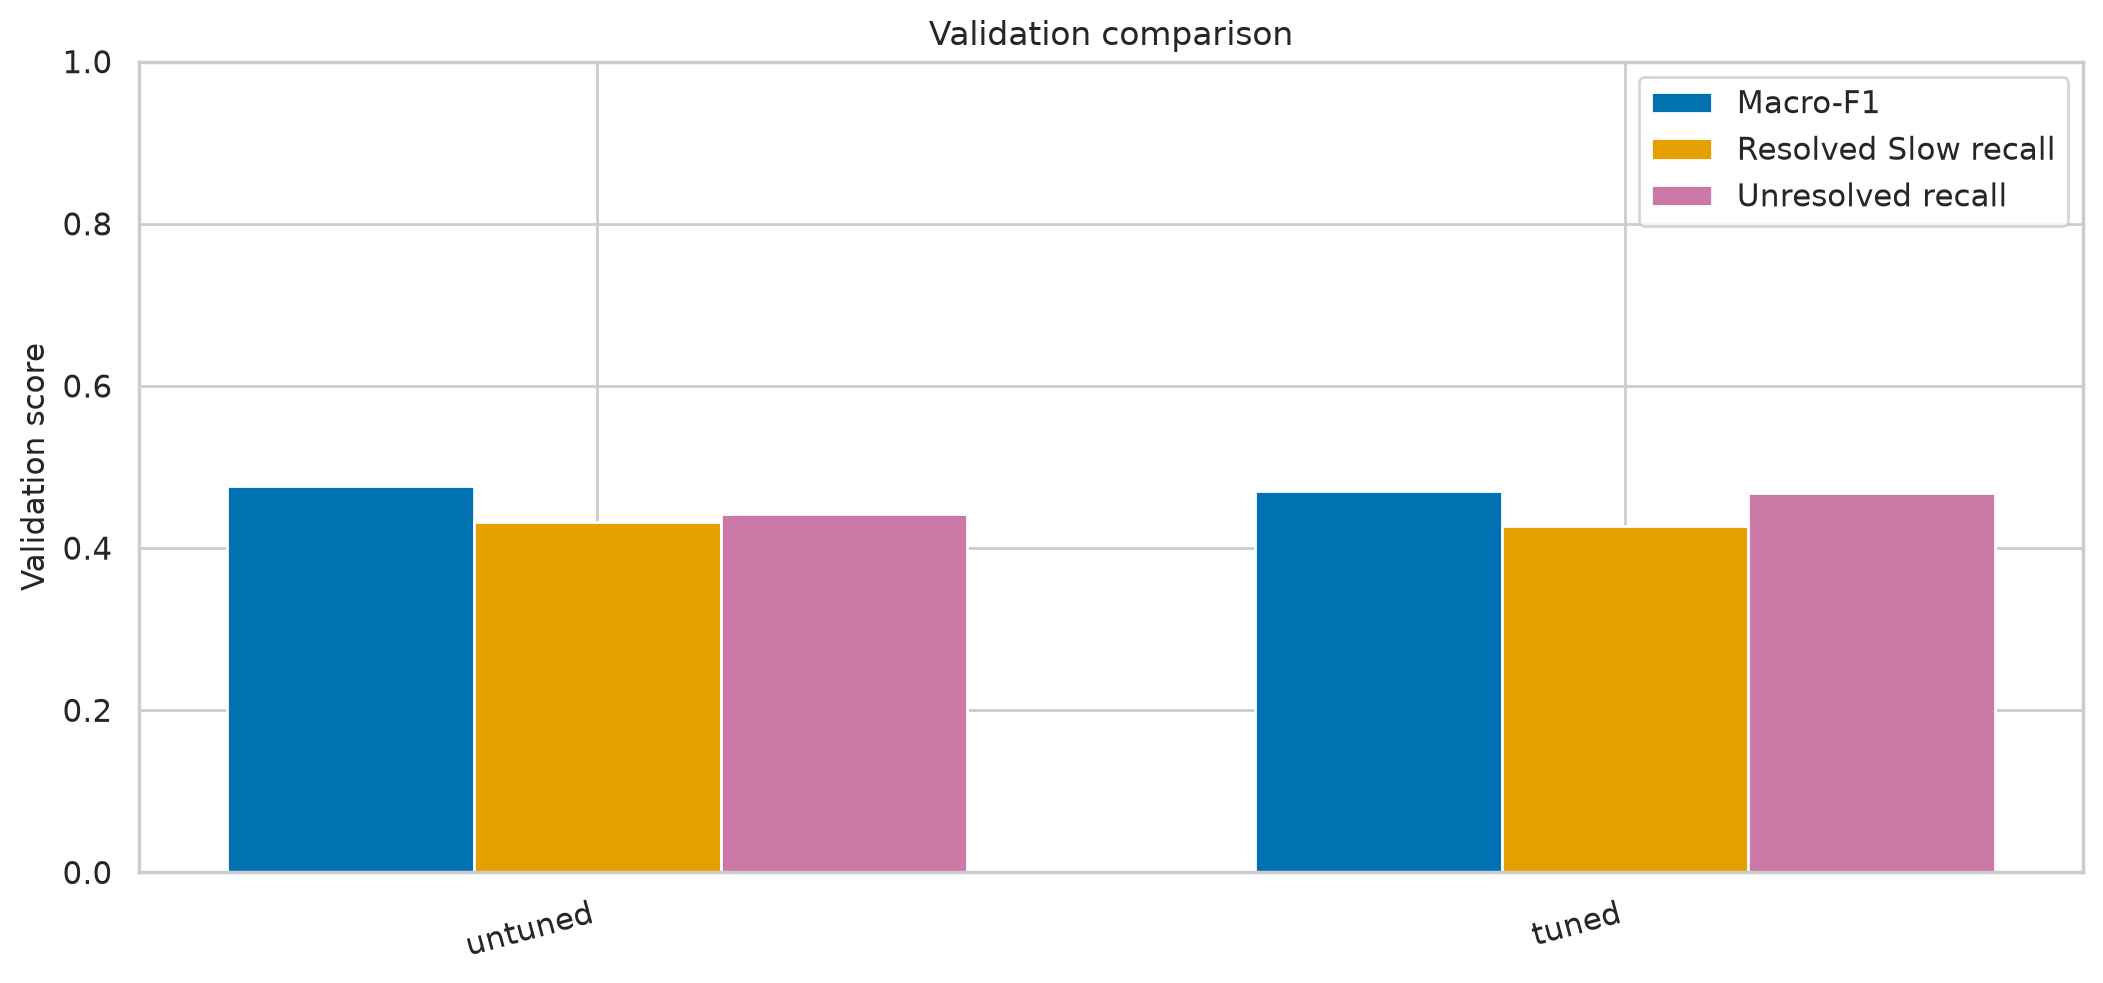

In [4]:
def setting_from_row(row):
    return {
        "learning_rate": float(row["learning_rate"]),
        "max_leaf_nodes": int(row["max_leaf_nodes"]),
        "min_samples_leaf": int(row["min_samples_leaf"]),
        "l2_regularization": float(row["l2_regularization"]),
    }


baseline_row = search_summary.loc[search_summary["origin"].eq("untuned_baseline")].iloc[0]
tuned_row = winner
candidates = {
    "untuned": {
        "parameters": setting_from_row(baseline_row),
        "max_iter": frozen_iteration(int(baseline_row["median_best_iteration"])),
        "training_fold_mean_macro_f1": float(baseline_row["mean_macro_f1"]),
    },
    "tuned": {
        "parameters": setting_from_row(tuned_row),
        "max_iter": frozen_iteration(int(tuned_row["median_best_iteration"])),
        "training_fold_mean_macro_f1": float(tuned_row["mean_macro_f1"]),
        "trial": int(tuned_row["trial"]),
        "origin": str(tuned_row["origin"]),
    },
}


def score_candidate(model, encoder, features, labels, model_name, split, fit_seconds):
    coded = encoder.transform(features)
    predicted = model.predict(coded)
    probabilities = probabilities_in_label_order(model.predict_proba(coded), model.classes_)
    summary, per_class = summarise_predictions(
        labels,
        predicted,
        probabilities,
        model=model_name,
        split=split,
        approval="approved",
        fit_seconds=fit_seconds,
    )
    return summary, per_class, predicted, probabilities


fitted = {}
metric_frames = []
class_frames = []
for name, spec in candidates.items():
    print(
        f"Refitting {name}: max_iter {spec['max_iter']}, parameters {spec['parameters']}",
        flush=True,
    )
    encoder, model, fit_seconds = fit_frozen_boosting(
        X_train,
        y_train,
        spec["parameters"],
        max_iter=spec["max_iter"],
    )
    fitted[name] = {"encoder": encoder, "model": model, "fit_seconds": fit_seconds}
    for split_name, features, labels in (
        ("train", X_train, y_train),
        ("validation", X_validation, y_validation),
    ):
        summary, per_class, _predicted, _probabilities = score_candidate(
            model, encoder, features, labels, name, split_name, fit_seconds
        )
        metric_frames.append(summary)
        class_frames.append(per_class)

candidate_metrics = pd.concat(metric_frames, ignore_index=True)
candidate_classes = pd.concat(class_frames, ignore_index=True)
display(candidate_metrics.round(3))
untuned_validation = float(
    candidate_metrics.loc[
        candidate_metrics["model"].eq("untuned") & candidate_metrics["split"].eq("validation"),
        "macro_f1",
    ].iloc[0]
)
tuned_validation = float(
    candidate_metrics.loc[
        candidate_metrics["model"].eq("tuned") & candidate_metrics["split"].eq("validation"),
        "macro_f1",
    ].iloc[0]
)
selected = choose_final_candidate(untuned_validation, tuned_validation)
print(f"Untuned validation macro-F1: {untuned_validation:.3f}")
print(f"Tuned validation macro-F1: {tuned_validation:.3f}")
print(f"Frozen candidate: {selected}")

frozen = {
    "champion_family": PROVISIONAL_CHAMPION,
    "selected": selected,
    "parameters": candidates[selected]["parameters"],
    "max_iter": int(candidates[selected]["max_iter"]),
    "early_stopping": False,
    "class_weight": "balanced",
    "features": full_feature_list(),
    "encoder": "TreeCategoryEncoder fit on the training period",
    "decision_rule": (
        "Keep the tuned refit only when its 2025 validation macro-F1 is higher "
        "than the untuned refit. A tie keeps the untuned settings."
    ),
    "untuned_validation_macro_f1": untuned_validation,
    "tuned_validation_macro_f1": tuned_validation,
    "untuned_training_fold_mean_macro_f1": candidates["untuned"]["training_fold_mean_macro_f1"],
    "tuned_training_fold_mean_macro_f1": candidates["tuned"]["training_fold_mean_macro_f1"],
    "tuned_trial": candidates["tuned"]["trial"],
    "comparator": comparison["comparator"],
    "comparator_phase5_validation_macro_f1": comparison["comparator_validation_macro_f1"],
    "comparator_rule": comparison["comparator_rule"],
    "excluded_from_comparator": comparison["excluded_from_comparator"],
    "split_id": comparison["split_id"],
    "locked_test_used_for_selection": False,
    "phase5_champion_validation_macro_f1": comparison["champion_validation_macro_f1"],
    "search_trials": TUNING_TRIALS,
    "search_seed": TUNING_SEED,
    "folds": list(TRAINING_FOLDS),
    "locked_test_scored": False,
}
freeze_path = config.TABLES_DIR / "06_frozen_decision.json"
save_json(frozen, freeze_path)
candidate_metrics.to_csv(config.TABLES_DIR / "06_candidate_metrics.csv", index=False)
candidate_classes.to_csv(config.TABLES_DIR / "06_candidate_per_class.csv", index=False)
print(f"Saved {freeze_path} before opening the locked test.")

validation_view = candidate_metrics.loc[candidate_metrics["split"].eq("validation")].copy()
validation_view["approval"] = "approved"
_figure, path = plot_validation_comparison(
    validation_view,
    filename="06_validation_comparison.png",
)
display(Image(filename=str(path)))


## 5. Locked test

The next cell reads the frozen decision, checks that the model in memory is that decision, and scores the locked test once. It does not fit another setting and it does not change the saved parameters.


,model,split,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,approval,fit_seconds
0,untuned,test,0.6,0.494,0.629,0.689,0.4,0.418,0.724,0.519,approved,5.026


,model,split,label,precision,recall,f1,support
0,untuned,test,Resolved Fast,0.829,0.689,0.752,287131
1,untuned,test,Resolved Slow,0.210,0.400,0.276,65522
2,untuned,test,Unresolved,0.495,0.418,0.454,69380


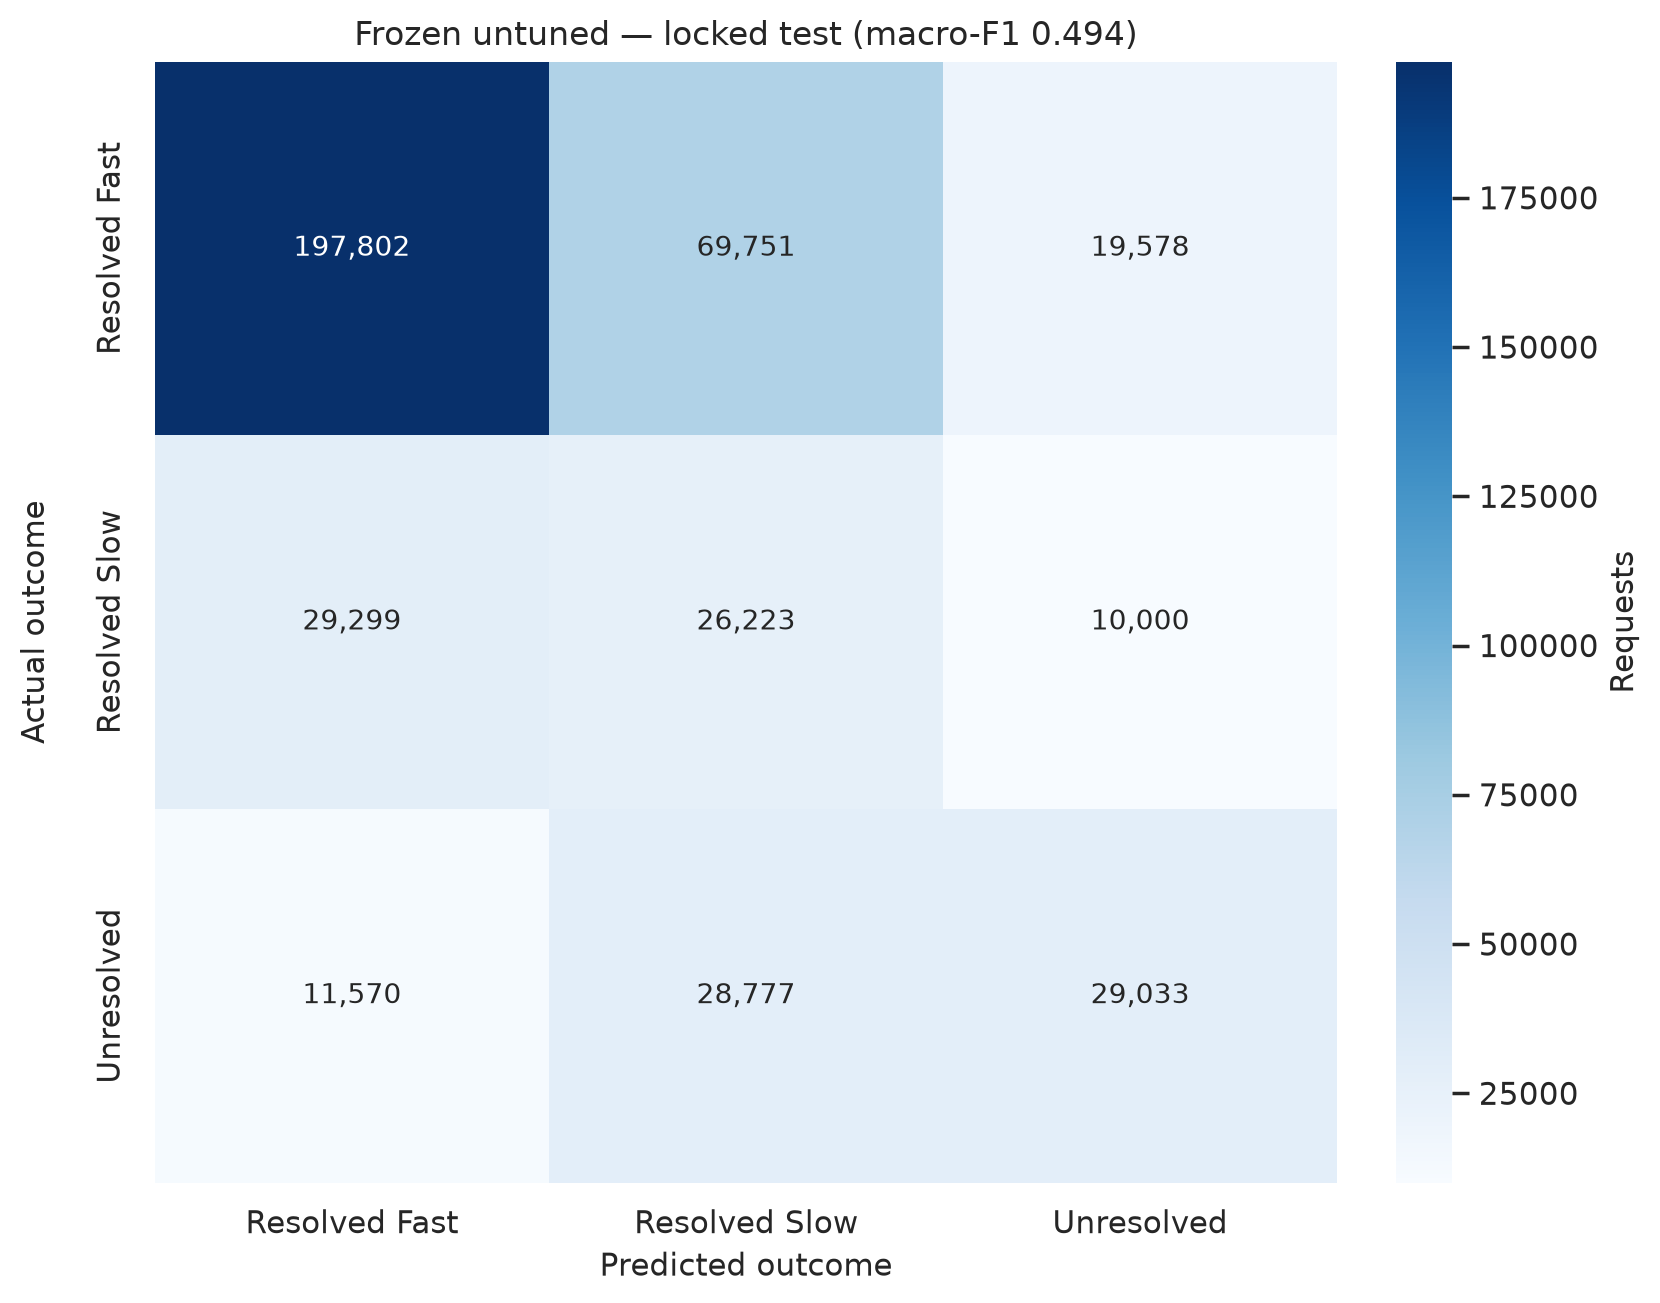

Saved /workspace/results/tables/06_test_predictions.parquet
Locked test scored once. The frozen parameters were not changed.
  model split  accuracy  macro_f1  weighted_f1  recall_resolved_fast  recall_resolved_slow  recall_unresolved  macro_roc_auc  macro_average_precision approval  fit_seconds
untuned  test       0.6     0.494        0.629                 0.689                   0.4              0.418          0.724                    0.519 approved        5.026


In [5]:
frozen_check = json.loads(freeze_path.read_text(encoding="utf-8"))
if frozen_check["locked_test_scored"]:
    raise RuntimeError("The frozen file already records a locked-test score. The model is not being refit.")
if frozen_check["selected"] != selected:
    raise RuntimeError("The frozen decision does not match the candidate chosen in this session.")
chosen_fit = fitted[selected]
if int(chosen_fit["model"].max_iter) != int(frozen_check["max_iter"]):
    raise RuntimeError("The in-memory iteration cap does not match the frozen decision.")
if bool(chosen_fit["model"].early_stopping):
    raise RuntimeError("The frozen model must not keep early stopping turned on.")

coded_test = chosen_fit["encoder"].transform(X_test)
test_predicted = chosen_fit["model"].predict(coded_test)
test_probabilities = probabilities_in_label_order(
    chosen_fit["model"].predict_proba(coded_test),
    chosen_fit["model"].classes_,
)
test_summary, test_per_class = summarise_predictions(
    y_test,
    test_predicted,
    test_probabilities,
    model=frozen_check["selected"],
    split="test",
    approval="approved",
    fit_seconds=chosen_fit["fit_seconds"],
    locked_test_authorised=True,
)
test_scores = classification_scores(y_test, test_predicted)
_figure, confusion_path = plot_confusion_matrix(
    test_scores["confusion_matrix"],
    list(config.TARGET_LABELS),
    f"Frozen {selected} — locked test (macro-F1 {test_scores['macro_f1']:.3f})",
    "06_confusion_locked_test.png",
)
display(test_summary.round(3))
display(test_per_class.round(3))
display(Image(filename=str(confusion_path)))

predictions = pd.DataFrame(
    {
        "source_index": test_index.astype(np.int64),
        "y_true": y_test,
        "champion_predicted": test_predicted,
        "p_resolved_fast": test_probabilities[:, 0],
        "p_resolved_slow": test_probabilities[:, 1],
        "p_unresolved": test_probabilities[:, 2],
    }
)
predictions_path = config.TABLES_DIR / "06_test_predictions.parquet"
predictions.to_parquet(predictions_path, index=False)
test_summary.to_csv(config.TABLES_DIR / "06_locked_test_summary.csv", index=False)
test_per_class.to_csv(config.TABLES_DIR / "06_locked_test_per_class.csv", index=False)
frozen_check["locked_test_scored"] = True
frozen_check["locked_test_macro_f1"] = float(test_summary["macro_f1"].iloc[0])
save_json(frozen_check, freeze_path)
print(f"Saved {predictions_path}")
print("Locked test scored once. The frozen parameters were not changed.")
print(test_summary.round(3).to_string(index=False))
